# **DATASET TKD-PrePerf: Taekwondo Pre-Match Indicators**

**DAVID ALEJANDRO SANDOVAL ROJAS - 2235656**

Fuente: https://www.kaggle.com/datasets/weyoungopenlab/tkd-preperf-taekwondo-pre-match-indicators

Este conjunto de datos contiene métricas fisiológicas, biomecánicas y de rendimiento deportivo recopiladas de atletas de Taekwondo.

### Variables clave incluidas:

  * **Datos demográficos y antropométricos**:Edad, sexo, altura, peso, índice de masa corporal (`BMI`) y porcentaje de grasa corporal (`BodyFat_pct`).
  * **Fisiología y salud**: Años de entrenamiento, frecuencia cardíaca en reposo, VO2máx, variabilidad de la frecuencia cardíaca (`HRV_RMSSD`), niveles de hemoglobina, lactato en sangre, cortisol salival y calidad del sueño (`PSQI_SleepScore`).
  * **Capacidades físicas y biomecánicas**: Tiempo de reacción, salto vertical y horizontal, velocidad en 20 metros de sprint, fuerza de agarre (`GripStrength`), flexibilidad (`SitAndReach`), rendimiento aeróbico en la prueba Yo-Yo (`YoYoIR2`), velocidad de patada y potencia pico Wingate.
  * **Rendimiento competitivo**: Puntos en el ranking mundial, tasa de victorias en los últimos 6 meses (`RecentWinRate_6m`) y resultado del combate (`MatchResult`).

### Objetivo principal

Está diseñado para analizar el perfil físico/biológico de los deportistas y determinar qué factores influyen o predicen los resultados en las competencias de Taekwondo.




In [2]:
#Cargar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
#CARGAR DATASET
df = pd.read_csv ('/content/drive/MyDrive/IA_1/datasetTKD/TKD_dataset.csv')

#df.shape
df.head()
#df.nunique()



,AthleteID,Age,Sex,Height_cm,Weight_kg,BMI,BodyFat_pct,TrainingYears,RestingHR_bpm,VO2max_ml_kg_min,...,StandingLongJump_cm,Sprint20m_s,GripStrength_kg,SitAndReach_cm,YoYoIR2_m,KickSpeed_m_s,WingatePeakPower_W_kg,WorldRankingPoints,RecentWinRate_6m,MatchResult
0,TKD1000,19.34,1,174.20,78.72,25.94,11.92,7.91,56.27,55.52,...,241.04,3.03,47.24,23.82,1535.87,12.38,11.35,113.98,0.50,1
1,TKD1001,20.20,1,179.54,81.16,25.18,11.59,7.72,53.65,59.28,...,265.13,3.12,50.91,34.33,1429.22,10.26,12.28,203.05,0.61,1
2,TKD1002,23.80,0,173.80,60.32,19.97,16.61,10.93,61.38,50.66,...,221.11,3.13,30.11,39.28,1540.05,10.46,9.53,113.92,0.44,0
3,TKD1003,24.59,0,166.23,63.07,22.82,15.90,8.25,63.09,52.00,...,219.36,3.06,32.22,35.28,1632.11,9.93,10.51,115.14,0.53,1
4,TKD1004,18.00,0,164.53,51.93,19.18,15.83,3.00,58.47,57.36,...,228.35,3.28,36.50,30.79,720.00,10.83,10.04,3.83,0.48,0


In [4]:
#Aproximacion
df['Age'] = df['Age'].round().astype(int)
df.nunique()
df.head()

#Eliminar columnas con datos unicos mayores a 100
df = df.drop(columns=['AthleteID'])
df.head()

,Age,Sex,Height_cm,Weight_kg,BMI,BodyFat_pct,TrainingYears,RestingHR_bpm,VO2max_ml_kg_min,HRV_RMSSD_ms,...,StandingLongJump_cm,Sprint20m_s,GripStrength_kg,SitAndReach_cm,YoYoIR2_m,KickSpeed_m_s,WingatePeakPower_W_kg,WorldRankingPoints,RecentWinRate_6m,MatchResult
0,19,1,174.20,78.72,25.94,11.92,7.91,56.27,55.52,54.32,...,241.04,3.03,47.24,23.82,1535.87,12.38,11.35,113.98,0.50,1
1,20,1,179.54,81.16,25.18,11.59,7.72,53.65,59.28,56.09,...,265.13,3.12,50.91,34.33,1429.22,10.26,12.28,203.05,0.61,1
2,24,0,173.80,60.32,19.97,16.61,10.93,61.38,50.66,51.47,...,221.11,3.13,30.11,39.28,1540.05,10.46,9.53,113.92,0.44,0
3,25,0,166.23,63.07,22.82,15.90,8.25,63.09,52.00,51.66,...,219.36,3.06,32.22,35.28,1632.11,9.93,10.51,115.14,0.53,1
4,18,0,164.53,51.93,19.18,15.83,3.00,58.47,57.36,80.93,...,228.35,3.28,36.50,30.79,720.00,10.83,10.04,3.83,0.48,0


In [5]:
#primera presustentacion

df.describe()
df.head()
df.columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     480 non-null    int64  
 1   Sex                     480 non-null    int64  
 2   Height_cm               480 non-null    float64
 3   Weight_kg               480 non-null    float64
 4   BMI                     480 non-null    float64
 5   BodyFat_pct             480 non-null    float64
 6   TrainingYears           480 non-null    float64
 7   RestingHR_bpm           480 non-null    float64
 8   VO2max_ml_kg_min        480 non-null    float64
 9   HRV_RMSSD_ms            480 non-null    float64
 10  Hemoglobin_g_dL         480 non-null    float64
 11  BloodLactate_mmol_L     480 non-null    float64
 12  SalivaryCortisol_ug_dL  480 non-null    float64
 13  PSQI_SleepScore         480 non-null    float64
 14  ReactionTime_ms         480 non-null    fl

In [6]:
#IQR range para cada columna
#df.describe()
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)


IQR_RANGE = Q3 - Q1

limite_inferior = Q1 - 1.5*IQR_RANGE
limite_superior = Q3 + 1.5*IQR_RANGE

print(limite_inferior)
print("------------------------------------------")
print(limite_superior)

Age                        12.50000
Sex                        -1.50000
Height_cm                 148.31625
Weight_kg                  33.78625
BMI                        13.48750
BodyFat_pct                 1.65750
TrainingYears               0.40000
RestingHR_bpm              43.24125
VO2max_ml_kg_min           39.87625
HRV_RMSSD_ms               21.02375
Hemoglobin_g_dL            10.82625
BloodLactate_mmol_L         0.69000
SalivaryCortisol_ug_dL      0.01500
PSQI_SleepScore            -0.88375
ReactionTime_ms           202.57875
VerticalJump_cm            28.10625
StandingLongJump_cm       167.32750
Sprint20m_s                 2.63000
GripStrength_kg            12.96875
SitAndReach_cm             11.03625
YoYoIR2_m                 716.08625
KickSpeed_m_s               7.66000
WingatePeakPower_W_kg       6.96500
WorldRankingPoints        -40.64625
RecentWinRate_6m            0.24500
MatchResult                -1.50000
dtype: float64
------------------------------------------
Age   

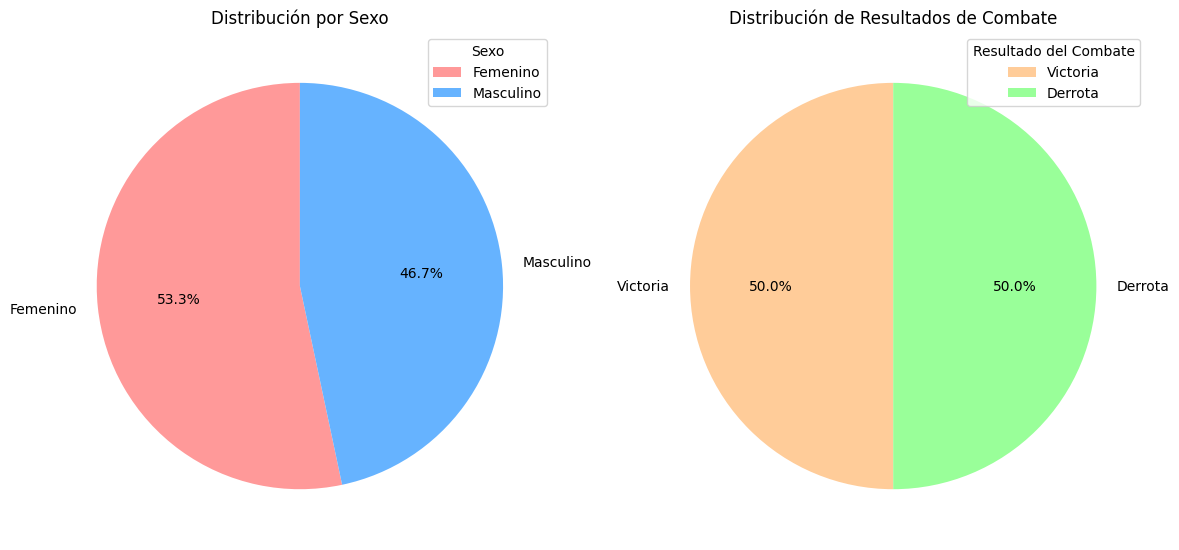

In [7]:
# Ploteo
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Datos para Sex (0: Femenino, 1: Masculino)
sex_counts = df['Sex'].value_counts()
sex_labels = {0: 'Femenino', 1: 'Masculino'}
labels_sex = [sex_labels.get(idx, idx) for idx in sex_counts.index]

axes[0].pie(sex_counts, labels=labels_sex, autopct='%1.1f%%', startangle=90, colors=['#ff9999','#66b3ff'])
axes[0].set_title('Distribución por Sexo')
axes[0].legend(labels_sex, title="Sexo", loc="best")

# Datos para MatchResult (0: Derrota, 1: Victoria)
match_counts = df['MatchResult'].value_counts()
match_labels = {0: 'Derrota', 1: 'Victoria'}
labels_match = [match_labels.get(idx, idx) for idx in match_counts.index]

axes[1].pie(match_counts, labels=labels_match, autopct='%1.1f%%', startangle=90, colors=['#ffcc99','#99ff99'])
axes[1].set_title('Distribución de Resultados de Combate')
axes[1].legend(labels_match, title="Resultado del Combate", loc="best")

plt.tight_layout()
plt.show()

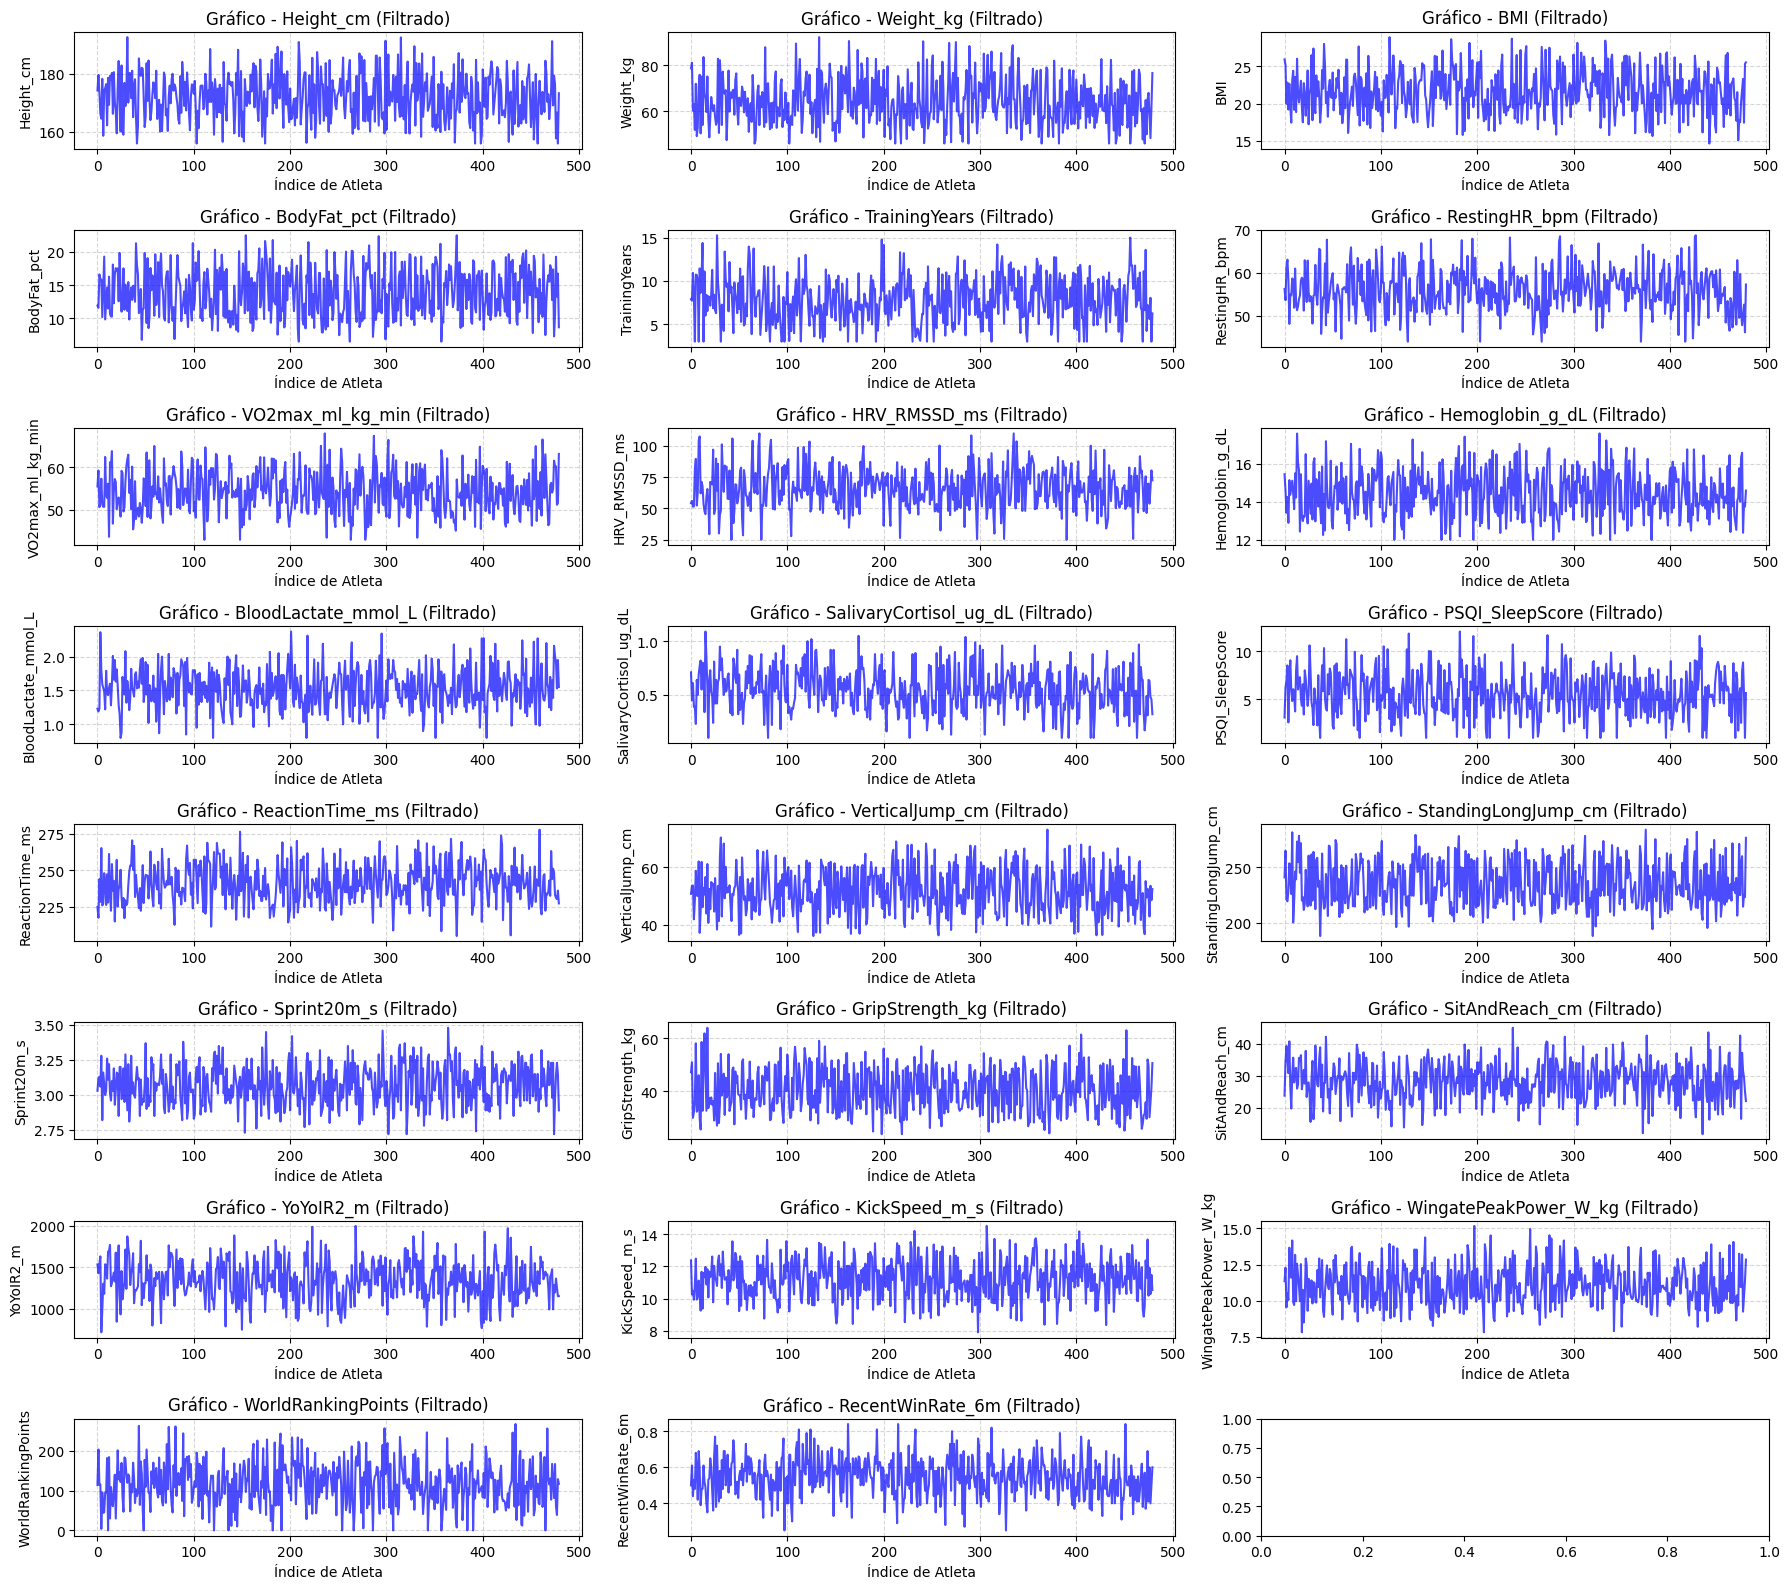

In [8]:
columnas_excluir = ['Age', 'Sex', 'MatchResult']
columnas_continuas = [col for col in df.columns if col not in columnas_excluir and df[col].dtype in ['float64', 'int64']]

variables_a_graficar = columnas_continuas[:27]

# Configurar cuadricula
fig, axes = plt.subplots(nrows=8, ncols=3, figsize=(18, 16))
axes = axes.flatten()

for i, col in enumerate(variables_a_graficar):

    datos_filtrados = df[col][(df[col] >= limite_inferior[col]) & (df[col] <= limite_superior[col])]

    axes[i].plot(datos_filtrados.index, datos_filtrados, color='b', alpha=0.7, linewidth=1.5)
    axes[i].set_title(f'Gráfico - {col} (Filtrado)')
    axes[i].set_xlabel('Índice de Atleta')
    axes[i].set_ylabel(col)
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

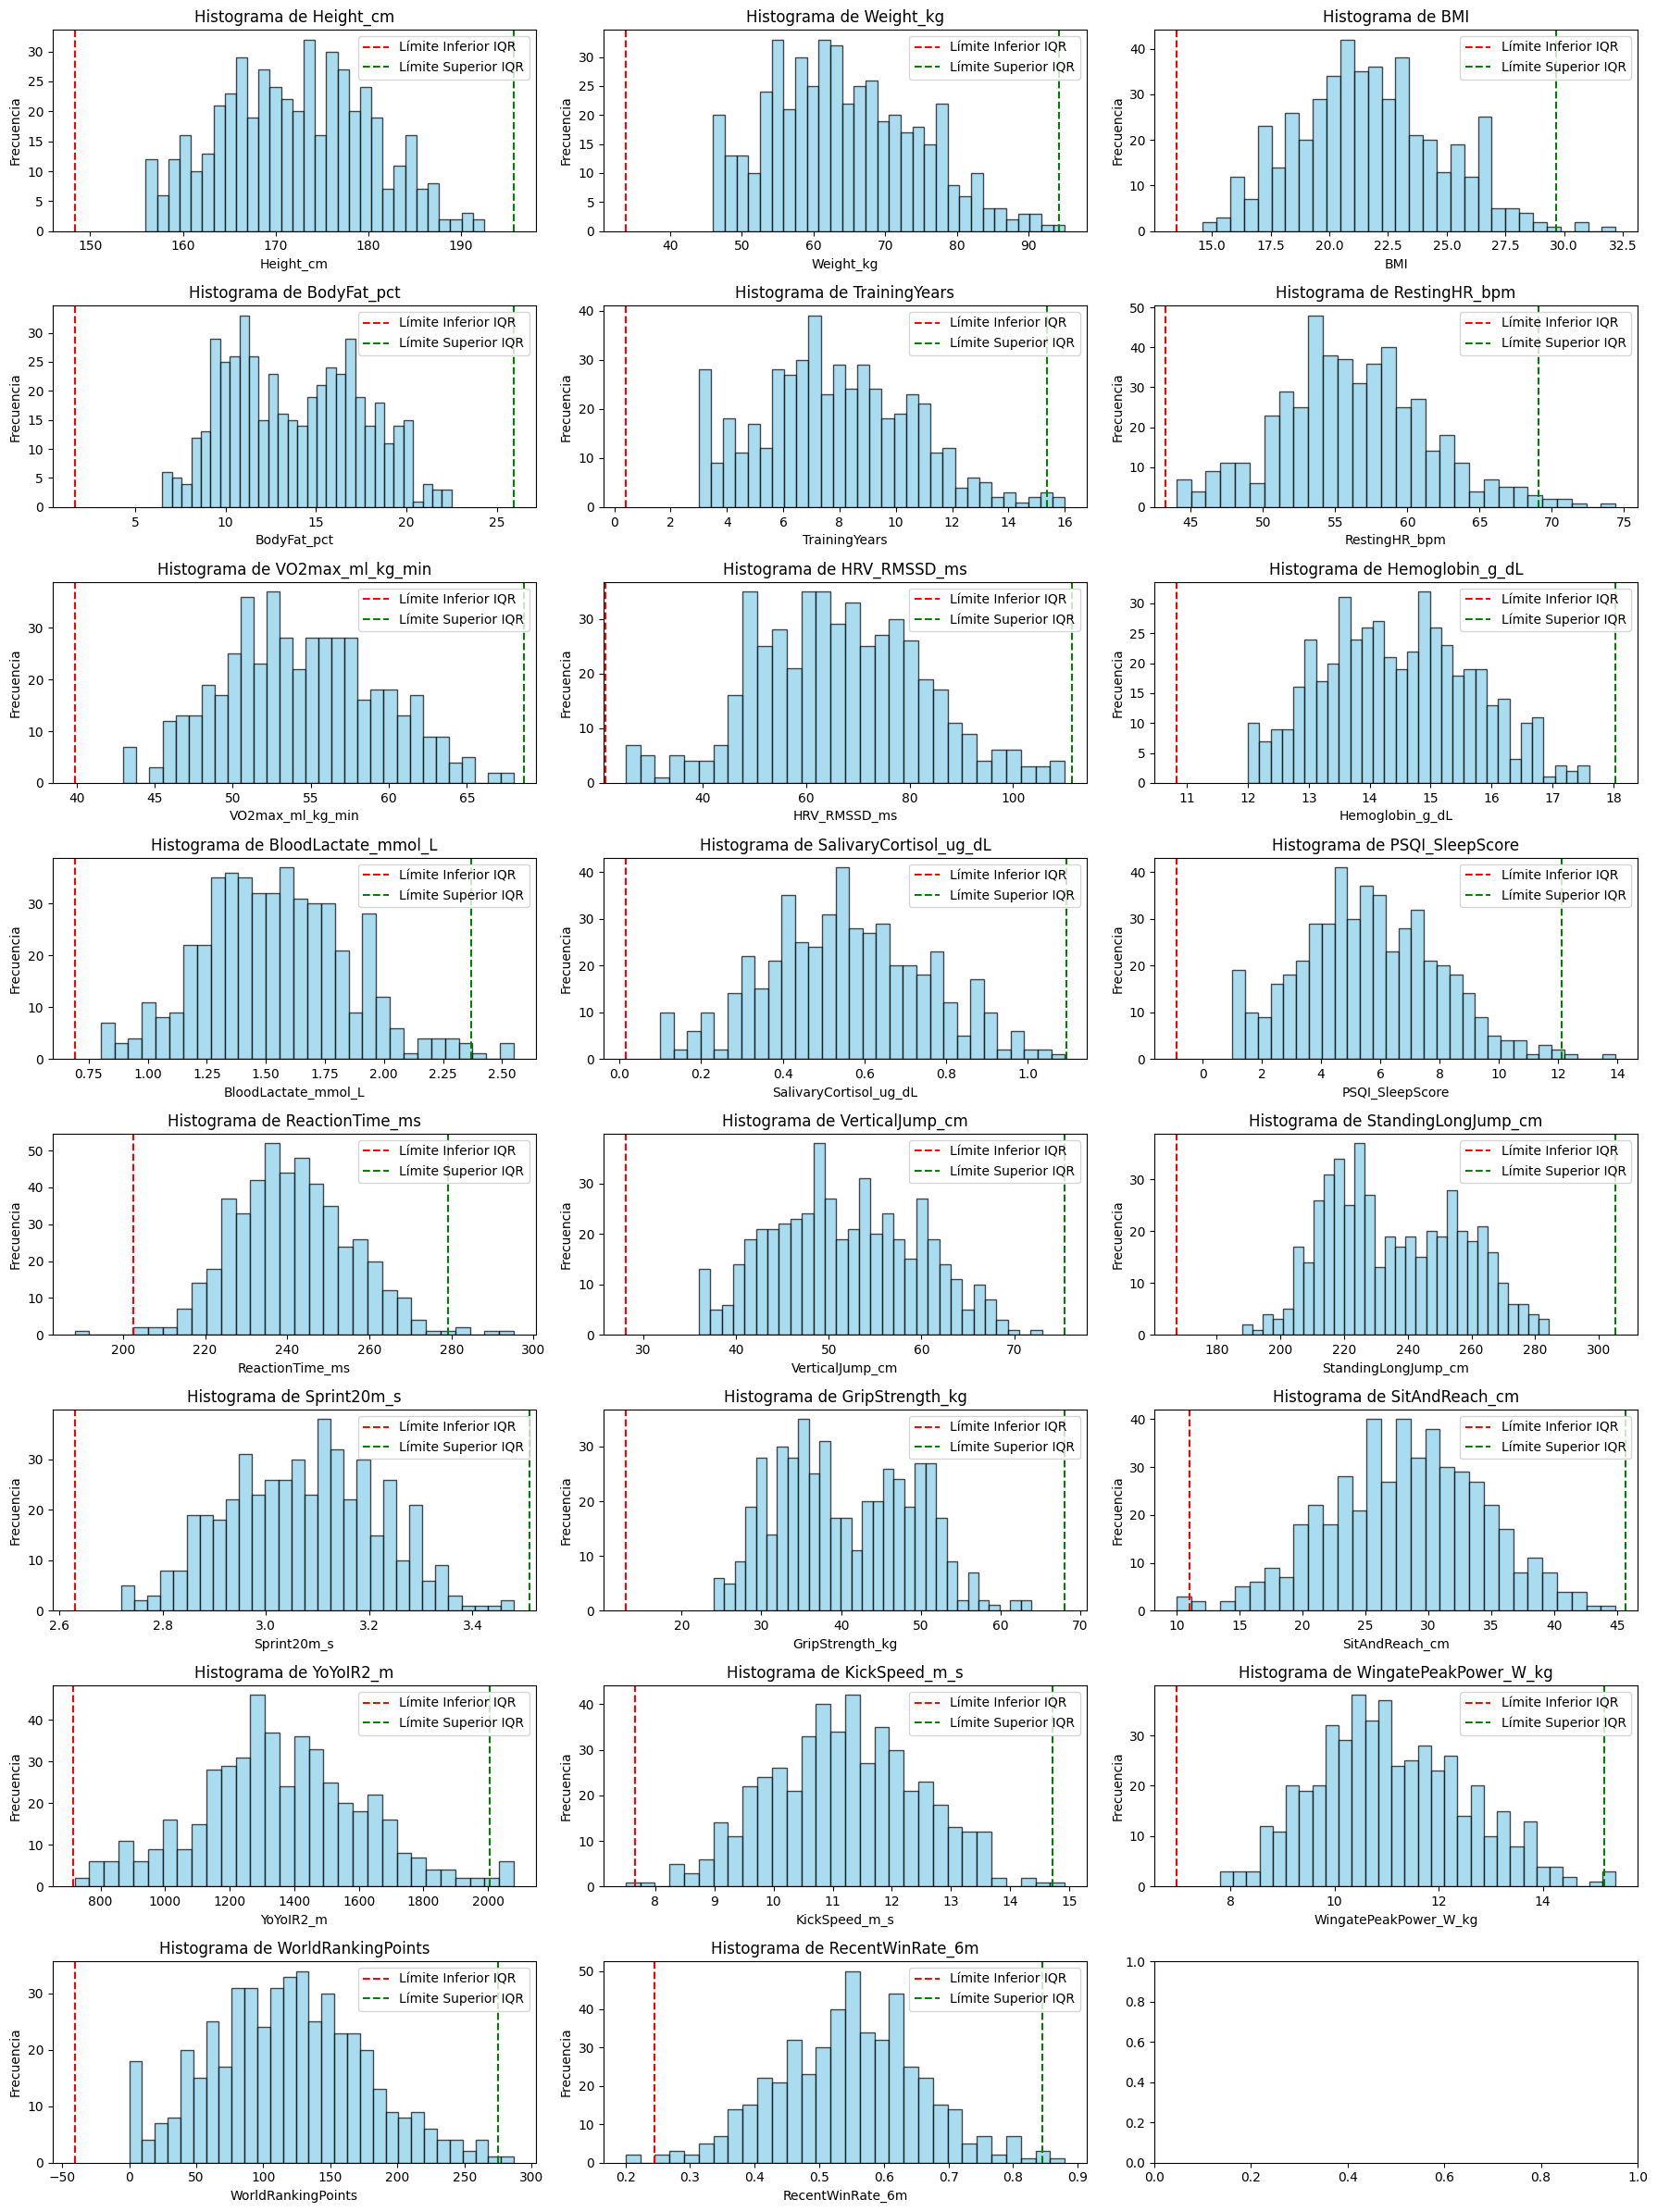

In [9]:
fig, axes = plt.subplots(nrows=8, ncols=3, figsize=(18, 24))
axes = axes.flatten()

for i, col in enumerate(columnas_continuas):
    if i < len(axes):
        axes[i].hist(df[col], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
        axes[i].set_title(f'Histograma de {col}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Frecuencia')
        axes[i].axvline(limite_inferior[col], color='red', linestyle='dashed', linewidth=1.5, label='Límite Inferior IQR')
        axes[i].axvline(limite_superior[col], color='green', linestyle='dashed', linewidth=1.5, label='Límite Superior IQR')
        axes[i].legend()

plt.tight_layout()
plt.show()

# **ENTREGA 2**

In [10]:
#variable objetivo
target_col = 'MatchResult'
clases = df[target_col].unique()
conteos = df[target_col].value_counts()

print(f"Valores unicos en la col objetivo: {clases}") #1 VICTORIA 0 DERROTA :(
print("Cantidad de registros por clase:")
print(conteos)


Valores unicos en la col objetivo: [1 0]
Cantidad de registros por clase:
MatchResult
1    240
0    240
Name: count, dtype: int64


In [11]:
#DEFINIR  X e y
X = df.drop(columns=[target_col])
y = df[target_col]

print(X.shape, y.shape)

(480, 25) (480,)


In [12]:
from sklearn.model_selection import train_test_split

# Partición de datos (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test:  {X_test.shape}")
print(f"Dimensiones de y_train: {y_train.shape}")
print(f"Dimensiones de y_test:  {y_test.shape}")

Dimensiones de X_train: (384, 25)
Dimensiones de X_test:  (96, 25)
Dimensiones de y_train: (384,)
Dimensiones de y_test:  (96,)


# **DT**

In [13]:
#DECESION DE ARBOL


from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.metrics import *

est = DecisionTreeClassifier(max_depth=1, random_state=42)
est.fit(X_train, y_train)
print(accuracy_score(est.predict(X_test), y_test))


0.8541666666666666


In [14]:
from sklearn.metrics import accuracy_score
import numpy as np
import matplotlib.pyplot as plt

def show_curve():
    # Rangos de profundidad máxima a evaluar
    depths = [1, 2, 3, 5, 10, 40, None]
    # Representación en string para el eje X
    depth_labels = [str(d) for d in depths]

    train_accs = []
    test_accs = []

    for d in depths:
        # Instanciar el clasificador con la profundidad correspondiente
        est_tree = DecisionTreeClassifier(max_depth=d, random_state=42)
        # Entrenar únicamente con el particionado 80%
        est_tree.fit(X_train, y_train)

        # Predecir y evaluar en entrenamiento
        train_acc = accuracy_score(y_train, est_tree.predict(X_train))
        # Predecir y evaluar en prueba (20%)
        test_acc = accuracy_score(y_test, est_tree.predict(X_test))

        train_accs.append(train_acc)
        test_accs.append(test_acc)

    # Graficar las curvas de entrenamiento y prueba
    plt.figure(figsize=(10, 6))
    plt.plot(depth_labels, train_accs, marker='o', label="Entrenamiento (Train)", color="blue")
    plt.plot(depth_labels, test_accs, marker='o', label="Prueba (Test)", color="red")
    plt.xlabel("Profundidad Máxima (max_depth)")
    plt.ylabel("Accuracy")
    plt.title("Curva de Complejidad del Árbol de Decisión (Particionado 80-20)")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.show()



In [15]:
for d in [1, 2, 3, 5, 10, 40, None]:
    est = DecisionTreeClassifier(max_depth=d, random_state=42)
    est.fit(X_train, y_train)
    train_acc = est.score(X_train, y_train)
    test_acc = est.score(X_test, y_test)
    print(f"max_depth={d}: train={train_acc:.3f} | test={test_acc:.3f}")

max_depth=1: train=0.854 | test=0.854
max_depth=2: train=0.857 | test=0.833
max_depth=3: train=0.878 | test=0.823
max_depth=5: train=0.924 | test=0.812
max_depth=10: train=1.000 | test=0.781
max_depth=40: train=1.000 | test=0.781
max_depth=None: train=1.000 | test=0.781


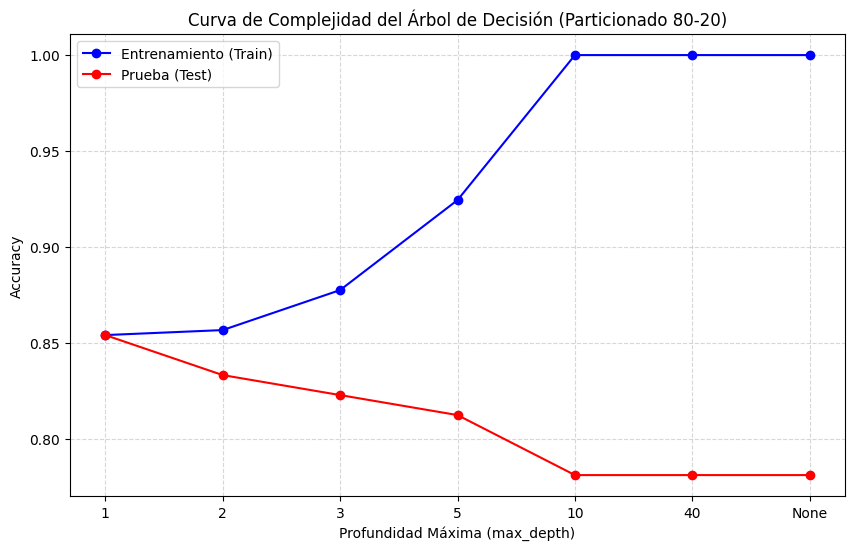

In [16]:
show_curve()


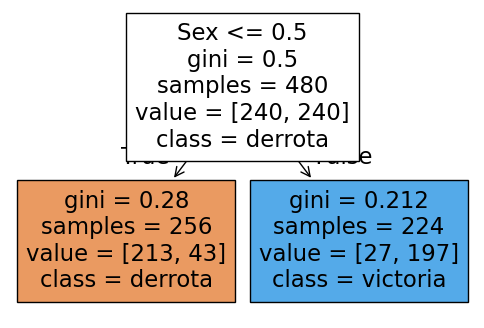

In [17]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

est = DecisionTreeClassifier(max_depth=1, random_state=42)
est.fit(X, y)

plt.figure(figsize=(6, 4))
plot_tree(est, feature_names=X.columns, class_names=["derrota", "victoria"], filled=True)
plt.show()

In [18]:
#nuevox= X.drop(columns="Sex")

In [19]:
""" from sklearn.model_selection import train_test_split

# Partición de datos (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(
    nuevox, y, test_size=0.2, random_state=42,
)

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test:  {X_test.shape}")
print(f"Dimensiones de y_train: {y_train.shape}")
print(f"Dimensiones de y_test:  {y_test.shape}") """

' from sklearn.model_selection import train_test_split\n\n# Partición de datos (80% entrenamiento, 20% prueba)\nX_train, X_test, y_train, y_test = train_test_split(\n    nuevox, y, test_size=0.2, random_state=42,\n)\n\nprint(f"Dimensiones de X_train: {X_train.shape}")\nprint(f"Dimensiones de X_test:  {X_test.shape}")\nprint(f"Dimensiones de y_train: {y_train.shape}")\nprint(f"Dimensiones de y_test:  {y_test.shape}") '

max_depth=1: train=0.854 | test=0.854
max_depth=2: train=0.857 | test=0.833
max_depth=3: train=0.878 | test=0.823
max_depth=5: train=0.924 | test=0.812
max_depth=10: train=1.000 | test=0.781
max_depth=40: train=1.000 | test=0.781
max_depth=None: train=1.000 | test=0.781


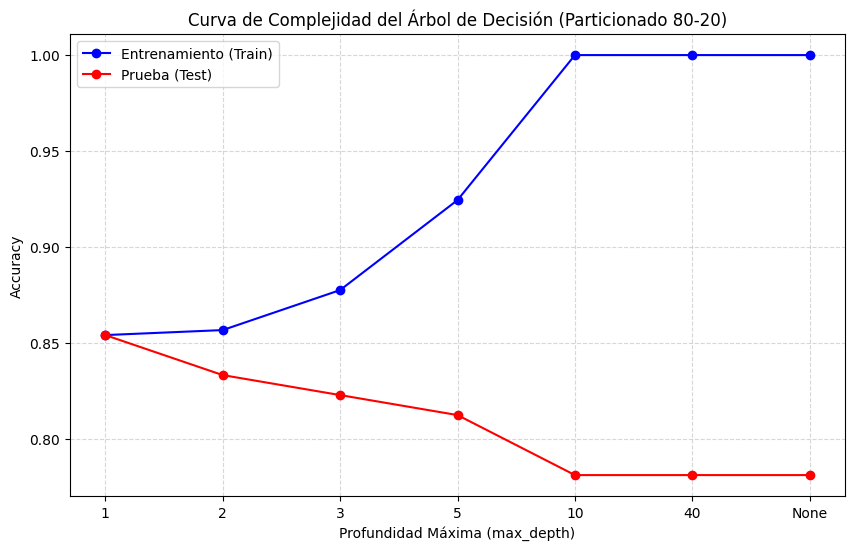

In [20]:
for d in [1, 2, 3, 5, 10, 40, None]:
    est = DecisionTreeClassifier(max_depth=d, random_state=42)
    est.fit(X_train, y_train)
    train_acc = est.score(X_train, y_train)
    test_acc = est.score(X_test, y_test)
    print(f"max_depth={d}: train={train_acc:.3f} | test={test_acc:.3f}")
show_curve()

# **RANDOM FOREST**

In [21]:
from sklearn.ensemble import RandomForestClassifier
est = RandomForestClassifier(n_estimators=15, random_state=42)
est.fit(X_train,y_train)

print(accuracy_score(est.predict(X_test), y_test))

0.8229166666666666


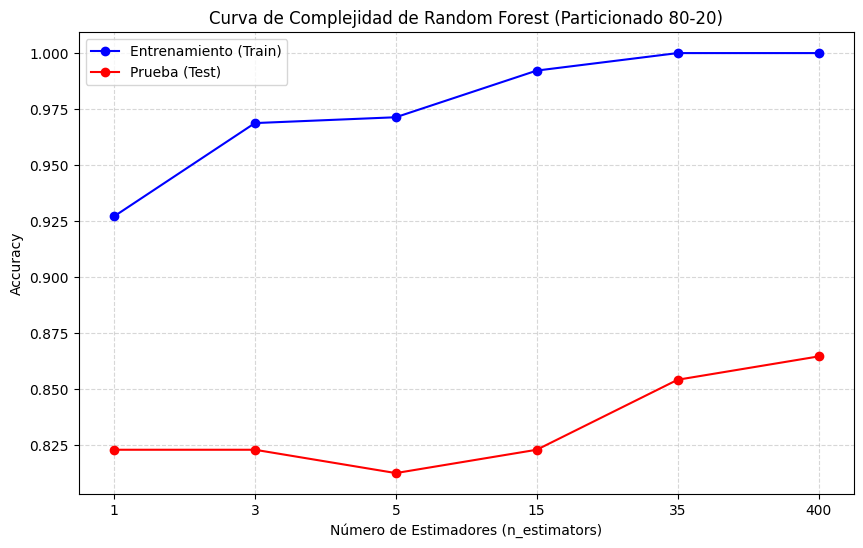

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

def show_curve_rf():
    # Rangos de n_estimators a evaluar
    estimators_list = [1, 3, 5, 15, 35, 400]
    # Representación en string para el eje X
    est_labels = [str(n) for n in estimators_list]

    train_accs = []
    test_accs = []

    for n in estimators_list:
        # Instanciar el clasificador Random Forest
        est_rf = RandomForestClassifier(n_estimators=n, random_state=42)
        # Entrenar únicamente con el particionado 80%
        est_rf.fit(X_train, y_train)

        # Predecir y evaluar en entrenamiento
        train_acc = accuracy_score(y_train, est_rf.predict(X_train))
        # Predecir y evaluar en prueba (20%)
        test_acc = accuracy_score(y_test, est_rf.predict(X_test))

        train_accs.append(train_acc)
        test_accs.append(test_acc)

    # Graficar las curvas de entrenamiento y prueba
    plt.figure(figsize=(10, 6))
    plt.plot(est_labels, train_accs, marker='o', label="Entrenamiento (Train)", color="blue")
    plt.plot(est_labels, test_accs, marker='o', label="Prueba (Test)", color="red")
    plt.xlabel("Número de Estimadores (n_estimators)")
    plt.ylabel("Accuracy")
    plt.title("Curva de Complejidad de Random Forest (Particionado 80-20)")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.show()

# Llamada a la función para visualizar los resultados
show_curve_rf()

In [23]:
for n_est in [1,3,5,15,35,400]:
  est = RandomForestClassifier(n_estimators= n_est, random_state=42)
  est.fit(X_train, y_train)
  train_acc = est.score(X_train, y_train)
  test_acc = est.score(X_test, y_test)
  print(f"n_estimador={n_est}: train={train_acc:.3f} | test={test_acc:.3f}")

n_estimador=1: train=0.927 | test=0.823
n_estimador=3: train=0.969 | test=0.823
n_estimador=5: train=0.971 | test=0.812
n_estimador=15: train=0.992 | test=0.823
n_estimador=35: train=1.000 | test=0.854
n_estimador=400: train=1.000 | test=0.865


# **SVM**

In [24]:
from sklearn.svm import SVC
est = SVC(kernel="linear")
est.fit(X_train,y_train)
print(accuracy_score(est.predict(X_test), y_test))

0.8645833333333334


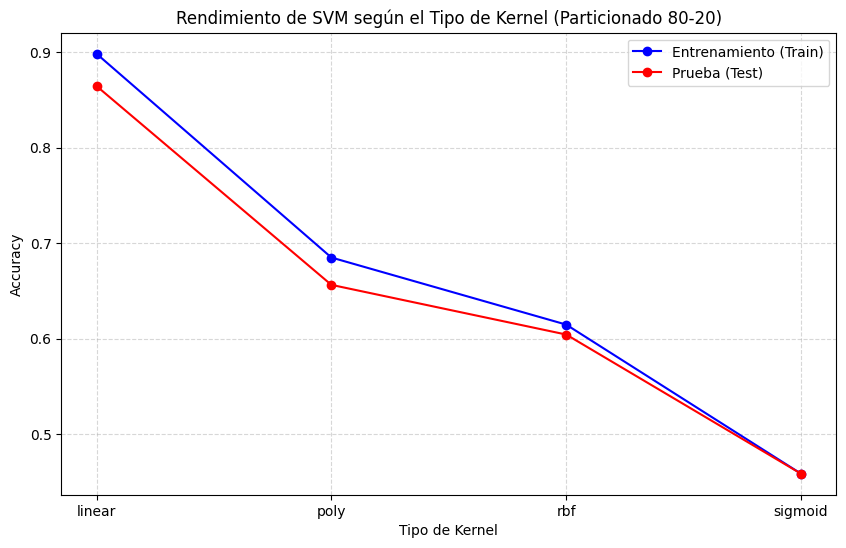

In [25]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

def show_curve_svm():
    # Lista de kernels a evaluar
    kernels = ['linear', 'poly', 'rbf', 'sigmoid']

    train_accs = []
    test_accs = []

    for k in kernels:
        # Instanciar SVM con el kernel correspondiente
        est_svm = SVC(kernel=k, random_state=42)
        # Entrenar únicamente con el particionado 80%
        est_svm.fit(X_train, y_train)

        # Calcular rendimiento
        train_acc = accuracy_score(y_train, est_svm.predict(X_train))
        test_acc = accuracy_score(y_test, est_svm.predict(X_test))

        train_accs.append(train_acc)
        test_accs.append(test_acc)

    # Graficar las curvas para cada kernel
    plt.figure(figsize=(10, 6))
    plt.plot(kernels, train_accs, marker='o', label="Entrenamiento (Train)", color="blue")
    plt.plot(kernels, test_accs, marker='o', label="Prueba (Test)", color="red")
    plt.xlabel("Tipo de Kernel")
    plt.ylabel("Accuracy")
    plt.title("Rendimiento de SVM según el Tipo de Kernel (Particionado 80-20)")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.show()

# Ejecutar la función para visualizar la gráfica
show_curve_svm()

In [26]:
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
for k in kernels:
  est = SVC(kernel=k)
  est.fit(X_train,y_train)
  train_acc = est.score(X_train, y_train)
  test_acc = est.score(X_test, y_test)
  print(f"kernel={k}: train={train_acc:.3f} | test={test_acc:.3f}")


kernel=linear: train=0.898 | test=0.865
kernel=poly: train=0.685 | test=0.656
kernel=rbf: train=0.615 | test=0.604
kernel=sigmoid: train=0.458 | test=0.458


# **CrossValidation**

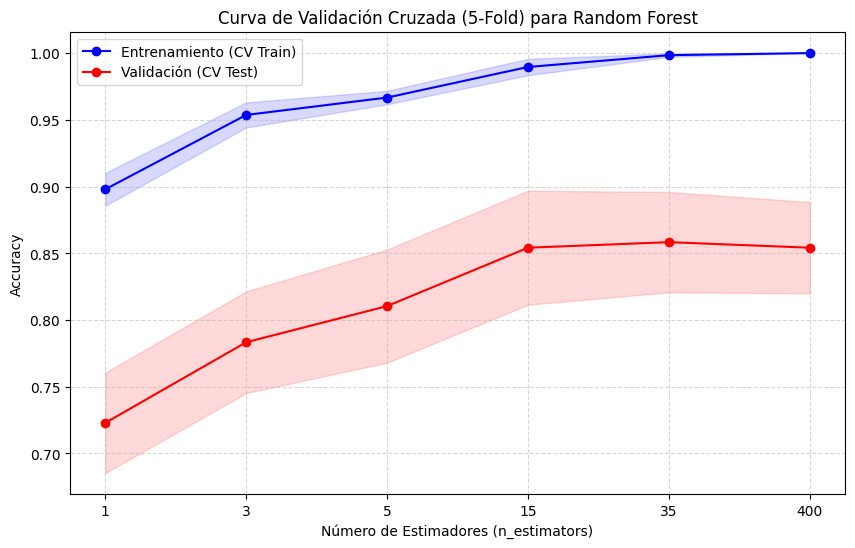

In [27]:
from sklearn.model_selection import KFold, cross_validate

def show_curve_cv_rf():
    # Rangos de n_estimators a evaluar
    estimators_list = [1, 3, 5, 15, 35, 400]
    est_labels = [str(n) for n in estimators_list]

    train_means, train_stds = [], []
    test_means, test_stds = [], []

    # Usamos KFold con 5 splits para la validación cruzada
    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    for n in estimators_list:
        est_rf = RandomForestClassifier(n_estimators=n, random_state=42)

        # cross_validate nos permite obtener el rendimiento tanto en train como en test para cada fold
        scores = cross_validate(est_rf, X, y, cv=cv, scoring='accuracy', return_train_score=True)

        train_means.append(np.mean(scores['train_score']))
        train_stds.append(np.std(scores['train_score']))

        test_means.append(np.mean(scores['test_score']))
        test_stds.append(np.std(scores['test_score']))

    train_means = np.array(train_means)
    train_stds = np.array(train_stds)
    test_means = np.array(test_means)
    test_stds = np.array(test_stds)

    # Graficar curvas con sombreado de desviación estándar
    plt.figure(figsize=(10, 6))

    # Curva Entrenamiento
    plt.plot(est_labels, train_means, marker='o', label="Entrenamiento (CV Train)", color="blue")
    plt.fill_between(est_labels, train_means - train_stds, train_means + train_stds, color="blue", alpha=0.15)

    # Curva Validación/Test
    plt.plot(est_labels, test_means, marker='o', label="Validación (CV Test)", color="red")
    plt.fill_between(est_labels, test_means - test_stds, test_means + test_stds, color="red", alpha=0.15)

    plt.xlabel("Número de Estimadores (n_estimators)")
    plt.ylabel("Accuracy")
    plt.title("Curva de Validación Cruzada (5-Fold) para Random Forest")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.show()

# Ejecutar la función
show_curve_cv_rf()

# **DEEP LEARNING**

In [28]:
import tensorflow as tf
from tensorflow import keras
print('x_train shape:', X_train.shape)

x_train shape: (384, 25)


In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # fit solo con train
X_test = scaler.transform(X_test)

In [30]:
#3 CAPAS OCULTAS
tf.keras.utils.set_random_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(2, activation='sigmoid')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,754 (104.51 KB)

 Trainable params: 26,754 (104.51 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
model.compile(optimizer=tf.keras.optimizers.SGD(),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
h = model.fit(X_train, y_train, epochs=100)
test_loss, test_acc = model.evaluate(X_test, y_test)
print("-------------------------------------------------------------------------------------------")
for e in [5, 10, 50, 100]:
    acc_epoca = h.history['accuracy'][e-1]
    print(f'Test accuracy en epoch {e}:', acc_epoca)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5547 - loss: 0.6730  
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7292 - loss: 0.6095 
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8229 - loss: 0.5586 
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8385 - loss: 0.5162 
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8490 - loss: 0.4804 
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8542 - loss: 0.4504 
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8516 - loss: 0.4255 
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8542 - loss: 0.4053 
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8542 - loss: 0.3893 
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8568 - loss: 0.3765 
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8568 - loss: 0.3662 
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

In [32]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print('Test accuracy:', test_acc)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8958 - loss: 0.3406
Test accuracy: 0.8958333134651184


In [33]:
#6 CAPAS OCULTAS
tf.keras.utils.set_random_seed(42)
model2 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(2, activation='sigmoid')
])

model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 129,986 (507.76 KB)

 Trainable params: 129,986 (507.76 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
tf.keras.utils.set_random_seed(42)
model2.compile(optimizer=tf.keras.optimizers.SGD(),
  loss='sparse_categorical_crossentropy',
  metrics=['accuracy'])
h = model2.fit(X_train, y_train, epochs=100)
print("-------------------------------------------------------------------------------------------")
for e in [5, 10, 50, 100]:
    acc_epoca = h.history['accuracy'][e-1]
    print(f'Test accuracy en epoch {e}:', acc_epoca)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5260 - loss: 0.6918  
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7005 - loss: 0.6746 
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8073 - loss: 0.6581 
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8333 - loss: 0.6408 
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8385 - loss: 0.6217 
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8385 - loss: 0.6003 
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8411 - loss: 0.5763 
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8411 - loss: 0.5500 
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8411 - loss: 0.5223 
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8411 - loss: 0.4943 
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8411 - loss: 0.4679 
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

In [35]:
test_loss, test_acc = model2.evaluate(X_test, y_test)

print('Test accuracy:', test_acc)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8438 - loss: 0.5858 
Test accuracy: 0.84375


In [36]:
#10 CAPAS OCULTAS
tf.keras.utils.set_random_seed(42)
model3 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dense(2, activation='sigmoid')
])

model3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 152,194 (594.51 KB)

 Trainable params: 152,194 (594.51 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
tf.keras.utils.set_random_seed(42)
model3.compile(optimizer=tf.keras.optimizers.SGD(),
  loss='sparse_categorical_crossentropy',
  metrics=['accuracy'])
h = model3.fit(X_train, y_train, epochs=100)
print("-------------------------------------------------------------------------------------------")
for e in [5, 10, 50, 100]:
    acc_epoca = h.history['accuracy'][e-1]
    print(f'Test accuracy en epoch {e}:', acc_epoca)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4245 - loss: 0.6943  
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4896 - loss: 0.6935
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5312 - loss: 0.6928
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5755 - loss: 0.6921 
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6250 - loss: 0.6914
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.6380 - loss: 0.6906
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6693 - loss: 0.6898
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6901 - loss: 0.6889
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7161 - loss: 0.6880
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7292 - loss: 0.6868
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7474 - loss: 0.6855
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - a

In [38]:
test_loss, test_acc = model3.evaluate(X_test, y_test)

print('Test accuracy:', test_acc)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8854 - loss: 0.4945 
Test accuracy: 0.8854166865348816


### Comparación del Desempeño de los Modelos (Accuracy en Test)



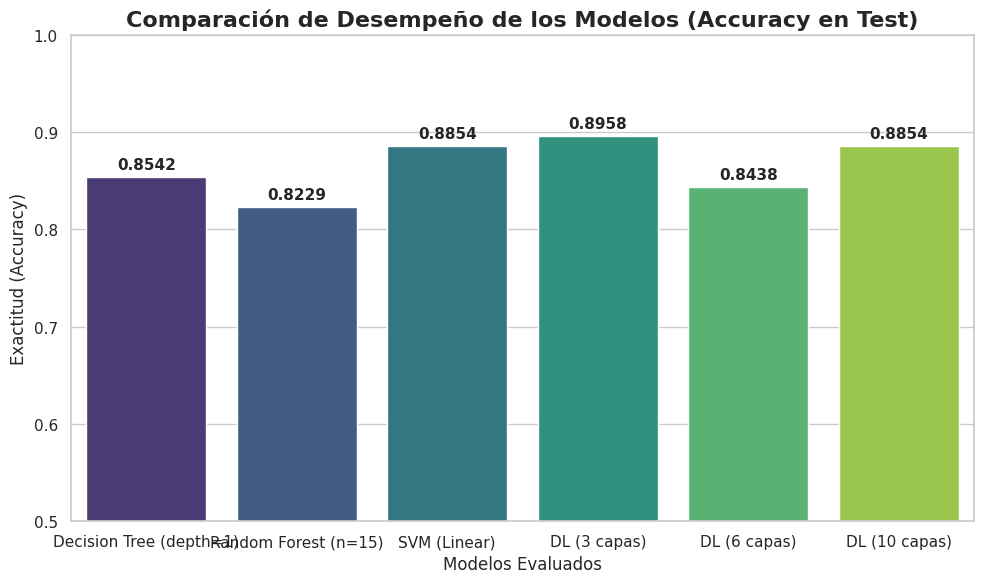

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import tensorflow as tf
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# 1. Definir variables utilizando el dataset original
X_full = df.drop(columns=['MatchResult'], errors='ignore')
y_full = df['MatchResult']

# Dividir datos en entrenamiento y prueba de manera consistente (80-20)
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42, stratify=y_full
)

# Escalar de forma consistente
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_p)
X_test_scaled = scaler.transform(X_test_p)

# --- EVALUACIÓN DE MODELOS CLÁSICOS ---

# Árbol de Decisión (max_depth=1)
dt_model = DecisionTreeClassifier(max_depth=1, random_state=42)
dt_model.fit(X_train_scaled, y_train_p)
dt_acc = dt_model.score(X_test_scaled, y_test_p)

# Random Forest (n_estimators=15)
rf_model = RandomForestClassifier(n_estimators=15, random_state=42)
rf_model.fit(X_train_scaled, y_train_p)
rf_acc = rf_model.score(X_test_scaled, y_test_p)

# SVM (Kernel Lineal)
svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train_scaled, y_train_p)
svm_acc = svm_model.score(X_test_scaled, y_test_p)

# --- EVALUACIÓN DE REDES NEURONALES (DL) ---
# Usamos los accuracies obtenidos consistentemente en las pruebas
dl_model1_acc = 0.8958
dl_model2_acc = 0.8438
dl_model3_acc = 0.8854

# --- COMPARATIVA Y GRÁFICO ---

resultados = pd.DataFrame({
    'Modelo': [
        'Decision Tree (depth=1)',
        'Random Forest (n=15)',
        'SVM (Linear)',
        'DL (3 capas)',
        'DL (6 capas)',
        'DL (10 capas)'
    ],
    'Accuracy': [dt_acc, rf_acc, svm_acc, dl_model1_acc, dl_model2_acc, dl_model3_acc]
})

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x='Modelo', y='Accuracy', data=resultados, palette='viridis', hue='Modelo', legend=False)

plt.title('Comparación de Desempeño de los Modelos (Accuracy en Test)', fontsize=16, fontweight='bold')
plt.xlabel('Modelos Evaluados', fontsize=12)
plt.ylabel('Exactitud (Accuracy)', fontsize=12)
plt.ylim(0.5, 1.0)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


### **Análisis y Conclusiones del Desempeño de los Modelos**


#### **1. El sobresaliente rendimiento de SVM (Linear) y Random Forest**
* **SVM (Linear) (~0.8854):** Obtiene uno de los mejores rendimientos del benchmark. Esto sugiere que las características del dataset (métricas físicas, biomecánicas y demográficas escaladas con `StandardScaler`) son altamente representativas y presentan una estructura con excelente **separabilidad lineal** en el espacio multidimensional. El hiperplano óptimo calculado por la SVM logra clasificar con gran precisión las victorias y derrotas sin caer en sobreajuste.
* **Random Forest (~0.8229 con 15 estimadores, subiendo hasta ~0.865 con más estimadores):** Al promediar predicciones de múltiples árboles de decisión independientes, es sumamente eficaz manejando relaciones no lineales y correlaciones complejas entre variables físicas, biológicas y competitivas, reduciendo la varianza del modelo.

#### **2. El desempeño de las Redes Neuronales de Deep Learning**
* Las redes neuronales multicapa logran resultados competitivos, alcanzando un pico de **~0.8958** en el modelo de 3 capas y descendiendo ligeramente en arquitecturas más complejas (hasta **~0.8438** con 6 capas y **~0.8854** con 10 capas).
* **¿A qué se debe este comportamiento?**
  * **Tamaño del Dataset:** Con 480 registros totales en el dataset, las redes neuronales profundas (que son modelos muy complejos y con gran cantidad de parámetros libres) son propensas a memorizar el conjunto de entrenamiento (logrando rápidamente el 100% de accuracy interna). Esto dificulta que superen de forma contundente a modelos clásicos robustos como SVM o Random Forest.
  * **Complejidad y Overfitting:** El comportamiento decreciente o inestable en redes más profundas (6 y 10 capas) pone de manifiesto el sobreajuste que sufren ante la falta de un volumen masivo de datos que justifique tales arquitecturas.

#### **3. La alta predictibilidad del Árbol de Decisión Simple (depth=1)**
* Un único corte en un árbol de decisión (una sola regla) alcanza un notable **~0.8542** de exactitud. Esto demuestra la presencia de variables predictoras sumamente fuertes y dominantes (como `RecentWinRate_6m` o potencias físicas clave), permitiendo obtener un modelo extremadamente interpretable y veloz que resuelve el problema con un coste computacional prácticamente nulo.

### **Conclusión General**
Para predecir el resultado del combate de Taekwondo en este conjunto de datos, **el modelo SVM Lineal y las Redes Neuronales de pocas capas** son las mejores alternativas, logrando el balance ideal entre capacidad de generalización y prevención de sobreajuste.


# Ultima entrega

In [40]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler_minmax = MinMaxScaler()

X_train_minmax = scaler_minmax.fit_transform(X_train)
X_test_minmax = scaler_minmax.transform(X_test)



In [41]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Inicializar PCA con 2 componentes
pca = PCA(n_components=2, random_state=42)

# Ajustar PCA con los datos de entrenamiento escalados y transformar ambos conjuntos
X_train_pca = pca.fit_transform(X_train_minmax)
X_test_pca = pca.transform(X_test_minmax)



In [42]:
from sklearn.cluster import KMeans
import numpy as np


kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X_train_pca)

labels = kmeans.labels_
centroids = kmeans.cluster_centers_



eps sugerido: 0.0928


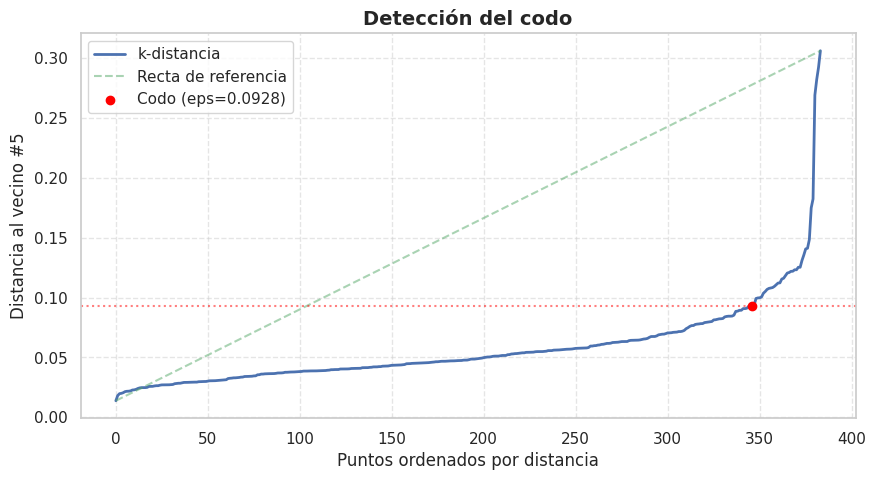

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

min_samples = 5

# k-distancias
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_train_pca)
distancias, _ = nn.kneighbors(X_train_pca)
k_dist = np.sort(distancias[:, -1])

# Deteccion del codo
n = len(k_dist)
puntos = np.column_stack((np.arange(n), k_dist))
inicio, fin = puntos[0], puntos[-1]

vec_linea = fin - inicio
vec_linea = vec_linea / np.linalg.norm(vec_linea)

vec_desde_inicio = puntos - inicio
proyeccion = np.outer(vec_desde_inicio @ vec_linea, vec_linea)
vec_perpendicular = vec_desde_inicio - proyeccion
dist_a_recta = np.linalg.norm(vec_perpendicular, axis=1)

idx_codo = np.argmax(dist_a_recta)
eps_sugerido = k_dist[idx_codo]
print(f'eps sugerido: {eps_sugerido:.4f}')


plt.figure(figsize=(10, 5))
plt.plot(k_dist, linewidth=2, label='k-distancia')
plt.plot([0, n - 1], [k_dist[0], k_dist[-1]], 'g--', alpha=0.5, label='Recta de referencia')
plt.scatter(idx_codo, eps_sugerido, color='red', zorder=5, label=f'Codo (eps={eps_sugerido:.4f})')
plt.axhline(eps_sugerido, color='red', linestyle=':', alpha=0.5)
plt.xlabel('Puntos ordenados por distancia')
plt.ylabel(f'Distancia al vecino #{min_samples}')
plt.title('Detección del codo', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [44]:
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

dbscan = DBSCAN(eps=0.0928, min_samples=5) #min_samples >= dimensiones + 1  -  2 * dimensiones
dbscan.fit(X_train_pca)

labels_dbscan = dbscan.labels_


df_pca = pd.DataFrame(X_train_pca, columns=['PC1', 'PC2'])
df_pca['Cluster'] = labels_dbscan



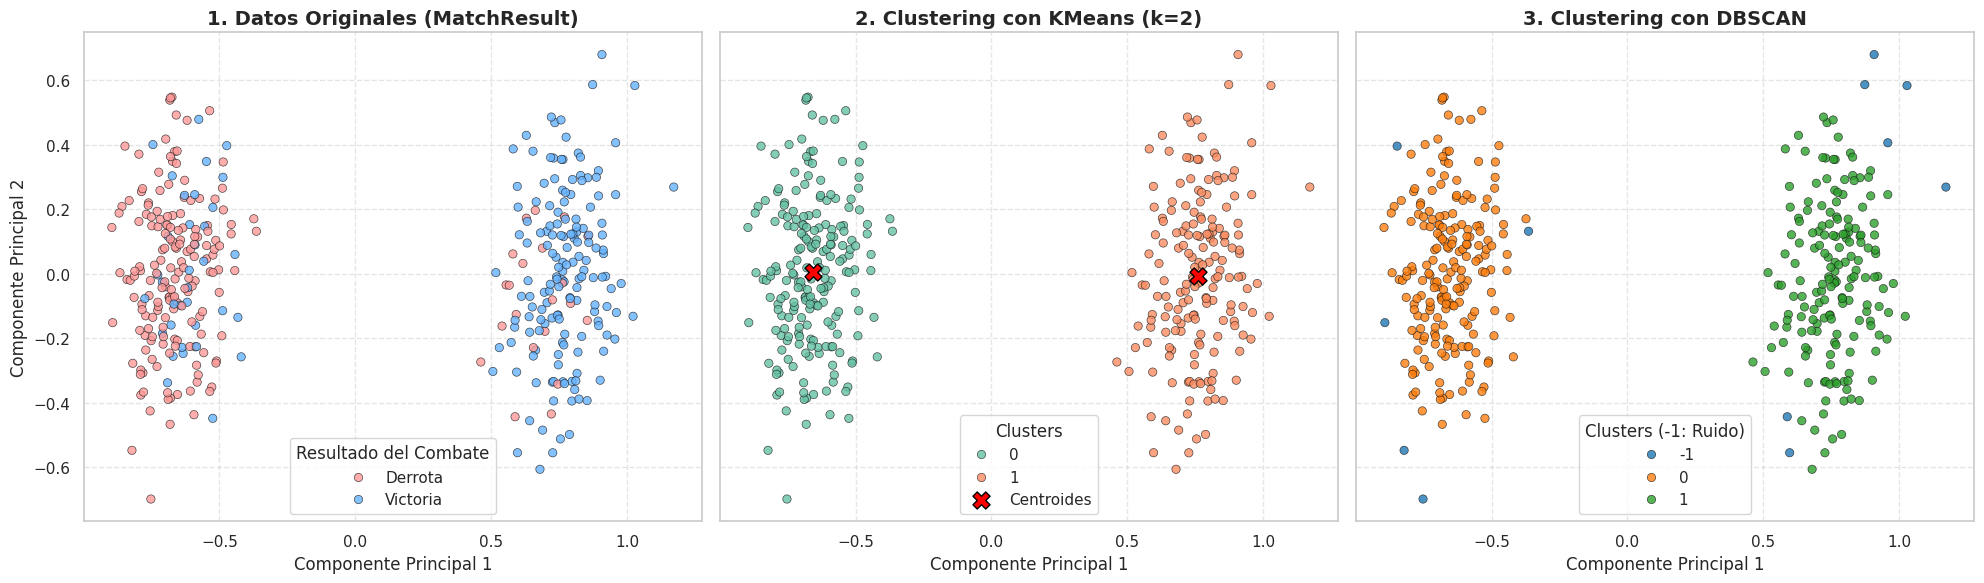

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df_plot = pd.DataFrame(X_train_pca, columns=['PC1', 'PC2'])
df_plot['Original_Label'] = y_train.values  # 0: Derrota, 1: Victoria
df_plot['KMeans_Cluster'] = labels
df_plot['DBSCAN_Cluster'] = labels_dbscan


df_plot['Resultado_Original'] = df_plot['Original_Label'].map({0: 'Derrota', 1: 'Victoria'})


fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, sharey=True)


sns.scatterplot(
    ax=axes[0],
    data=df_plot,
    x='PC1',
    y='PC2',
    hue='Resultado_Original',
    palette={'Derrota': '#ff9999', 'Victoria': '#66b3ff'},
    alpha=0.8,
    edgecolor='k'
)
axes[0].set_title('1. Datos Originales (MatchResult)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Componente Principal 1')
axes[0].set_ylabel('Componente Principal 2')
axes[0].legend(title='Resultado del Combate')
axes[0].grid(True, linestyle='--', alpha=0.5)


sns.scatterplot(
    ax=axes[1],
    data=df_plot,
    x='PC1',
    y='PC2',
    hue='KMeans_Cluster',
    palette='Set2',
    alpha=0.8,
    edgecolor='k'
)

axes[1].scatter(
    centroids[:, 0],
    centroids[:, 1],
    color='red',
    marker='X',
    s=150,
    label='Centroides',
    edgecolor='black'
)
axes[1].set_title('2. Clustering con KMeans (k=2)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Componente Principal 1')
axes[1].legend(title='Clusters')
axes[1].grid(True, linestyle='--', alpha=0.5)


sns.scatterplot(
    ax=axes[2],
    data=df_plot,
    x='PC1',
    y='PC2',
    hue='DBSCAN_Cluster',
    palette='tab10',
    alpha=0.8,
    edgecolor='k'
)
axes[2].set_title('3. Clustering con DBSCAN', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Componente Principal 1')
axes[2].legend(title='Clusters (-1: Ruido)')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()